# Crop AIRS to the greater North American domain

- **Input:** `Data/AIRS/SNDR.AQUA.AIRS.*.nc` (monthly L3 CLIMCAPS, 1° global grid)
- **Bounding box** (lon_min, lat_min, lon_max, lat_max): `-173.215130, 4.498592, -48.619584, 72.872428`
- **Output:** `Data/AIRS-cropped-greater-domain/<YYYYMM>.nc` (e.g. `200209.nc`), same naming as `Scripts/crop_airs.ipynb`

Cells: 1) config → 2) test: view one original file → 3) test: crop & save it → 4) test: read & view the cropped file → 5) crop all files.

In [1]:
# ── Config ────────────────────────────────────────────────────────────────────
import glob
import os
import re
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Paths are relative to this notebook (Scripts/greater-domain/)
PROJECT_DIR  = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
DATA_DIR     = os.path.join(PROJECT_DIR, "Data", "AIRS")
CROP_OUT_DIR = os.path.join(PROJECT_DIR, "Data", "AIRS-cropped-greater-domain")
assert os.path.isdir(DATA_DIR), f"Input folder not found: {DATA_DIR}  (cwd = {os.getcwd()})"
os.makedirs(CROP_OUT_DIR, exist_ok=True)

VARNAME = "co_mmr_midtrop"   # variable used for the visual checks

# Greater North American domain: lon_min, lat_min, lon_max, lat_max
LON_MIN_C, LAT_MIN_C, LON_MAX_C, LAT_MAX_C = -173.215130, 4.498592, -48.619584, 72.872428

all_airs_files = sorted(glob.glob(os.path.join(DATA_DIR, "SNDR.AQUA.AIRS.*.nc")))
print(f"Input : {DATA_DIR}  ({len(all_airs_files)} files)")
print(f"Output: {CROP_OUT_DIR}")


def ym_from_path(p):
    m = re.search(r'AIRS\.(\d{4})(\d{2})\d{2}\.', p)
    return (int(m.group(1)), int(m.group(2))) if m else None


def crop_ds(ds):
    """Crop every lat/lon variable to the bounding box (grid-cell centres inside the box)."""
    lon_mask = ((ds["lon"] >= LON_MIN_C) & (ds["lon"] <= LON_MAX_C)).values
    lat_mask = ((ds["lat"] >= LAT_MIN_C) & (ds["lat"] <= LAT_MAX_C)).values
    ds_crop = ds.isel(lon=lon_mask, lat=lat_mask)

    # Drop encodings tied to the original 180×360 grid (chunk sizes etc.), keep compression
    for v in ds_crop.variables.values():
        for k in ("chunksizes", "original_shape", "preferred_chunks", "source"):
            v.encoding.pop(k, None)

    ds_crop.attrs["crop_lon_min"] = LON_MIN_C
    ds_crop.attrs["crop_lon_max"] = LON_MAX_C
    ds_crop.attrs["crop_lat_min"] = LAT_MIN_C
    ds_crop.attrs["crop_lat_max"] = LAT_MAX_C
    return ds_crop


def plot_map(da, title, extent=None):
    """Map of a (lat, lon) field with the crop box drawn on top."""
    fig, ax = plt.subplots(figsize=(11, 6), subplot_kw={"projection": ccrs.PlateCarree()})
    mesh = ax.pcolormesh(da["lon"], da["lat"], da, transform=ccrs.PlateCarree(),
                         cmap="YlOrRd", shading="auto")
    ax.coastlines(linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4)
    ax.add_patch(mpatches.Rectangle((LON_MIN_C, LAT_MIN_C), LON_MAX_C - LON_MIN_C, LAT_MAX_C - LAT_MIN_C,
                                    fill=False, edgecolor="blue", linewidth=1.5, transform=ccrs.PlateCarree()))
    if extent is not None:
        ax.set_extent(extent, crs=ccrs.PlateCarree())
    else:
        ax.set_global()
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5)
    gl.top_labels = gl.right_labels = False
    fig.colorbar(mesh, ax=ax, shrink=0.7, label=f"{da.name} [{da.attrs.get('units', '')}]")
    ax.set_title(title)
    plt.show()

Input : d:\AIRS\harmonic-analysis\Data\AIRS  (279 files)
Output: d:\AIRS\harmonic-analysis\Data\AIRS-cropped-greater-domain


Test file: SNDR.AQUA.AIRS.20020901.M01.L3_CLIMCAPS_QCS.std.v02_38.G.210413100515.nc
Frozen({'orbit_pass': 2, 'air_pres': 100, 'lat': 180, 'lon': 360, 'air_pres_h2o': 66, 'surf_wnum_ir': 4, 'cld_pres_lay': 3, 'bnds_1d': 2, 'utc_tuple': 8})
lat -89.5 → 89.5,  lon -179.5 → 179.5


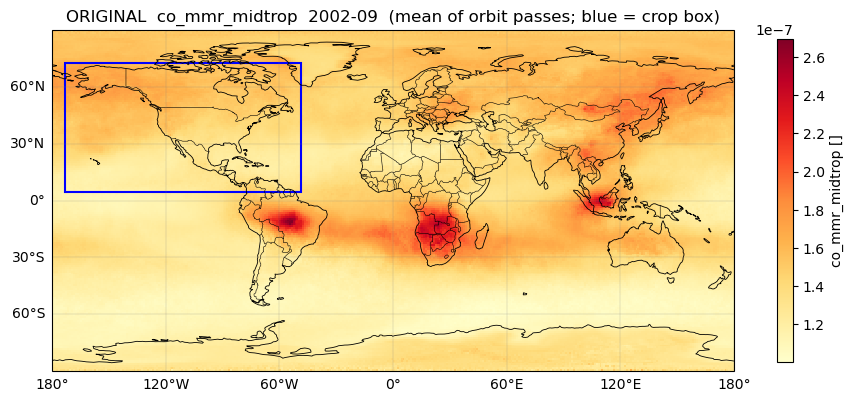

In [2]:
# ── TEST 1: read and visualise one original file ─────────────────────────────
test_file = all_airs_files[0]
print("Test file:", os.path.basename(test_file))

ds_test = xr.open_dataset(test_file, decode_timedelta=False)
print(ds_test.sizes)
print(f"lat {ds_test.lat.values[0]} → {ds_test.lat.values[-1]},  lon {ds_test.lon.values[0]} → {ds_test.lon.values[-1]}")

co_orig = ds_test[VARNAME].mean(dim="orbit_pass", skipna=True)
y, m = ym_from_path(test_file)
plot_map(co_orig, f"ORIGINAL  {VARNAME}  {y}-{m:02d}  (mean of orbit passes; blue = crop box)")

In [3]:
# ── TEST 2: crop the test file and save it ───────────────────────────────────
y, m = ym_from_path(test_file)
test_out = os.path.join(CROP_OUT_DIR, f"{y}{m:02d}.nc")

ds_test_crop = crop_ds(ds_test)
ds_test_crop.attrs["source_file"] = os.path.basename(test_file)
ds_test_crop.to_netcdf(test_out)
ds_test.close()

print("Saved →", test_out)
print(ds_test_crop.sizes)

Saved → d:\AIRS\harmonic-analysis\Data\AIRS-cropped-greater-domain\200209.nc
Frozen({'orbit_pass': 2, 'air_pres': 100, 'lat': 69, 'lon': 124, 'air_pres_h2o': 66, 'surf_wnum_ir': 4, 'cld_pres_lay': 3, 'bnds_1d': 2, 'utc_tuple': 8})


Frozen({'orbit_pass': 2, 'air_pres': 100, 'lat': 69, 'lon': 124, 'air_pres_h2o': 66, 'surf_wnum_ir': 4, 'cld_pres_lay': 3, 'bnds_1d': 2, 'utc_tuple': 8})
lat 4.5 → 72.5,  lon -172.5 → -49.5
{'crop_lon_min': np.float64(-173.21513), 'crop_lon_max': np.float64(-48.619584), 'crop_lat_min': np.float64(4.498592), 'crop_lat_max': np.float64(72.872428), 'source_file': 'SNDR.AQUA.AIRS.20020901.M01.L3_CLIMCAPS_QCS.std.v02_38.G.210413100515.nc'}


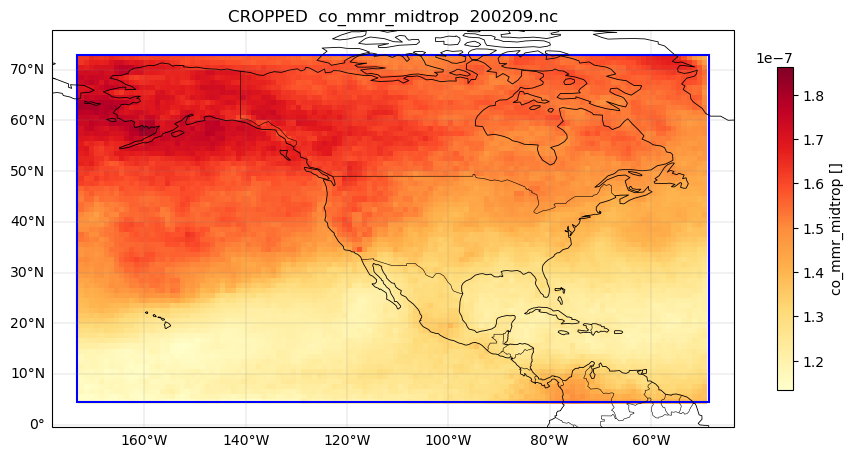

Identical to original subset: True


In [4]:
# ── TEST 3: read back and visualise the cropped file ─────────────────────────
ds_chk = xr.open_dataset(test_out, decode_timedelta=False)
print(ds_chk.sizes)
print(f"lat {ds_chk.lat.values[0]} → {ds_chk.lat.values[-1]},  lon {ds_chk.lon.values[0]} → {ds_chk.lon.values[-1]}")
print({k: v for k, v in ds_chk.attrs.items() if k.startswith("crop_") or k == "source_file"})

co_crop = ds_chk[VARNAME].mean(dim="orbit_pass", skipna=True)
pad = 5
plot_map(co_crop, f"CROPPED  {VARNAME}  {os.path.basename(test_out)}",
         extent=[LON_MIN_C - pad, LON_MAX_C + pad, LAT_MIN_C - pad, LAT_MAX_C + pad])

# Sanity check: cropped values identical to the original subset
orig_sub = co_orig.sel(lat=co_crop.lat, lon=co_crop.lon)
print("Identical to original subset:", np.allclose(orig_sub.values, co_crop.values, equal_nan=True))
ds_chk.close()

In [5]:
# ── Crop ALL AIRS files ───────────────────────────────────────────────────────
# Output: Data/AIRS-cropped-greater-domain/<YYYYMM>.nc  (e.g. 200209.nc, 200210.nc …)
OVERWRITE = False   # True → re-create files that already exist

saved, skipped = [], []

for f in all_airs_files:
    ym = ym_from_path(f)
    if ym is None:
        print(f"  [skip] Cannot parse date from: {os.path.basename(f)}")
        skipped.append(f)
        continue

    year, month = ym
    out_name = f"{year}{month:02d}.nc"
    out_path = os.path.join(CROP_OUT_DIR, out_name)

    if os.path.exists(out_path) and not OVERWRITE:
        print(f"  [exists] {out_name} – skipping")
        skipped.append(f)
        continue

    with xr.open_dataset(f, decode_timedelta=False) as ds:
        ds_crop = crop_ds(ds)
        ds_crop.attrs["source_file"] = os.path.basename(f)
        ds_crop.load()
    ds_crop.to_netcdf(out_path)

    print(f"  [saved] {out_name}  (lat {ds_crop.lat.values[0]:.2f}–{ds_crop.lat.values[-1]:.2f}, "
          f"lon {ds_crop.lon.values[0]:.2f}–{ds_crop.lon.values[-1]:.2f})")
    saved.append(out_name)

print(f"\nDone.  Saved {len(saved)} files  |  Skipped {len(skipped)} files")
print(f"Output folder: {CROP_OUT_DIR}")

  [exists] 200209.nc – skipping
  [saved] 200210.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200211.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200212.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200301.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200302.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200303.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200304.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200305.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200306.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200307.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200308.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200309.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200310.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200311.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200312.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200401.nc  (lat 4.50–72.50, lon -172.50–-49.50)
  [saved] 200402.nc  (lat 4.50–72.50, lo